
# Data Parsing


### 0: Load Existing Data from Local Files
Instead of re-scraping, we will load the datasets directly from the CSV files created in previous steps.

In [ ]:
import pandas as pd
import os

# Load the 5000 row sample
sample_path = 'waikato_dataset.csv'
if os.path.exists(sample_path):
    df_sample = pd.read_csv(sample_path)
    # Ensure 'text' column exists for analysis
    df_sample['text'] = df_sample['title'].fillna('') + ' ' + df_sample['abstract'].fillna('')
    print(f"Loaded sample data: {len(df_sample)} rows.")
else:
    print(f"Warning: {sample_path} not found.")

# Load the full dataset
full_path = 'waikato_full_dataset_16777.csv'
if os.path.exists(full_path):
    df_full = pd.read_csv(full_path)
    # Ensure 'text' column exists
    if 'text' not in df_full.columns:
        df_full['text'] = df_full['title'].fillna('') + ' ' + df_full['abstract'].fillna('')
    print(f"Loaded full data: {len(df_full)} rows.")
else:
    print(f"Warning: {full_path} not found.")

Loaded sample data: 5000 rows.
Loaded full data: 16777 rows.


In [ ]:
# Map 'df' to 'df_sample' to maintain compatibility with existing exploration cells
df = df_sample
display(df.head())

,record_id,title,authors,year,subjects,abstract,url,text
0,NaN,Characterizing porous microaggregates and soil...,"Huang, Doreen Yu-Tuan",2021,Science & Technology,Allophanic tephra-derived soils can sequester ...,NaN,Characterizing porous microaggregates and soil...
1,NaN,Sexual Desire in Women Presenting for Antiandr...,"Conaglen, Helen M.",2003,antiandrogen therapy,Women presenting with hirsuties/polycystic ova...,NaN,Sexual Desire in Women Presenting for Antiandr...
2,NaN,Aluminium content in near-shore sediments of L...,"Tempero, Grant Wayne",2019,NaN,The application of alum (aluminium sulphate) i...,NaN,Aluminium content in near-shore sediments of L...
3,NaN,Introduction,"Houlahan, Mark",2019,NaN,"When Dr Johnson, the 18• century critic, was a...",NaN,"Introduction When Dr Johnson, the 18• century ..."
4,NaN,Is peer review in academic publishing still wo...,"Jackson, Liz",2018,Peer review,Peer review is central to academic publishing....,NaN,Is peer review in academic publishing still wo...


**Initial  Scrape Flow**

> API → Fetch page → Parse items → Store rows → DataFrame → CSV




### 1: Install dependencies

In [ ]:
!pip install requests pandas tqdm

### 2: Imports

In [ ]:
import requests
import pandas as pd
from tqdm import tqdm
import time
import matplotlib.pyplot as plt
import seaborn as sns


### 3: Base API setup

In [ ]:
BASE_URL = "https://researchcommons.waikato.ac.nz/server/api/discover/search/objects"

HEADERS = {
    "Accept": "application/json"
}

TARGET_N = 5000   # change later to 10000+
PAGE_SIZE = 50

### 4: Fetch function (core scraper)

In [ ]:
def fetch_page(page=0, size=PAGE_SIZE, retries=3):
    params = {
        "size": size,
        "page": page
    }

    for i in range(retries):
        try:
            r = requests.get(BASE_URL, headers=HEADERS, params=params, timeout=10)

            if r.status_code == 200:
                data = r.json()
                # Debugging: Print a snippet of the raw response to check for 'id' structure
                # print(f"Page {page} raw data snippet (first item): {data.get('_embedded', {}).get('searchResult', {}).get('_embedded', {}).get('objects', [{}])[0]}")
                return data
            elif r.status_code == 429: # Too Many Requests
                print(f"Rate limit hit on page {page}. Retrying in {2**(i+1)} seconds...")
                time.sleep(2**(i+1))

        except requests.exceptions.RequestException as e:
            print(f"Error fetching page {page}, attempt {i+1}/{retries}: {e}")
            time.sleep(2**(i+1))

    print(f"Failed to fetch page {page} after {retries} attempts.")
    return None

### 5: Parse function (IMPORTANT)

In [ ]:
def parse_item(item):
    md = item.get("_embedded", {}).get("indexableObject", {}).get("metadata", {})

    def get(field):
        return md.get(field, [{}])[0].get("value", "") if field in md else ""

    record_id = item.get("id", "")
    if not record_id: # If direct item.id is empty or missing
        record_id = item.get("_embedded", {}).get("indexableObject", {}).get("id", "")

    # Debugging: If record_id is still not found, print the whole item to inspect its structure
    if not record_id:
        print(f"Warning: record_id not found for item. Printing full item for inspection:")
        print(item)

    return {
        "record_id": record_id,
        "title": get("dc.title"),
        "authors": get("dc.contributor.author"),
        "year": get("dc.date.issued"),
        "subjects": get("dc.subject"),
        "abstract": get("dc.description.abstract"),
        "url": item.get("_links", {}).get("self", {}).get("href", "")
    }

### 6: Main scraping loop (sample data)

In [ ]:
rows = []
page = 0

print("Starting scraping...")

while len(rows) < TARGET_N:
    data = fetch_page(page)

    if not data:
        break

    items = data["_embedded"]["searchResult"]["_embedded"]["objects"]

    for item in items:
        rows.append(parse_item(item))

    print(f"Page {page} → Total rows: {len(rows)}")

    page += 1
    time.sleep(0.5)  # avoid server overload

Starting scraping...
Page 0 → Total rows: 50
Page 1 → Total rows: 100
Page 2 → Total rows: 150
Page 3 → Total rows: 200
Page 4 → Total rows: 250
Page 5 → Total rows: 300
Page 6 → Total rows: 350
Page 7 → Total rows: 400
Page 8 → Total rows: 450
Page 9 → Total rows: 500
Page 10 → Total rows: 550
Page 11 → Total rows: 600
Page 12 → Total rows: 650
Page 13 → Total rows: 700
Page 14 → Total rows: 750
Page 15 → Total rows: 800
Page 16 → Total rows: 850
Page 17 → Total rows: 900
Page 18 → Total rows: 950
Page 19 → Total rows: 1000
Page 20 → Total rows: 1050
Page 21 → Total rows: 1100
Page 22 → Total rows: 1150
Page 23 → Total rows: 1200
Page 24 → Total rows: 1250
Page 25 → Total rows: 1300
Page 26 → Total rows: 1350
Page 27 → Total rows: 1400
Page 28 → Total rows: 1450
Page 29 → Total rows: 1500
Page 30 → Total rows: 1550
Page 31 → Total rows: 1600
Page 32 → Total rows: 1650
Page 33 → Total rows: 1700
Page 34 → Total rows: 1750
Page 35 → Total rows: 1800
Page 36 → Total rows: 1850
Page 37 → 

### 7: Convert to DataFrame

In [ ]:
df = pd.DataFrame(rows)

df.head()

,record_id,title,authors,year,subjects,abstract,url
0,7c6c8265-4f3d-4c3d-8451-eb65d2c53740,Characterizing porous microaggregates and soil...,"Huang, Doreen Yu-Tuan",2021,Science & Technology,Allophanic tephra-derived soils can sequester ...,
1,7c78f924-dde8-42b9-9bfa-aec701a6e8b5,Sexual Desire in Women Presenting for Antiandr...,"Conaglen, Helen M.",2003,antiandrogen therapy,Women presenting with hirsuties/polycystic ova...,
2,7c7f18d0-f376-4bb1-8667-25c6cf7cfdda,Aluminium content in near-shore sediments of L...,"Tempero, Grant Wayne",2019,,The application of alum (aluminium sulphate) i...,
3,7c87430b-93a6-47f7-b0ce-f0a12120885a,Introduction,"Houlahan, Mark",2019,,"When Dr Johnson, the 18• century critic, was a...",
4,7c87b197-d5d2-446e-ad1e-f365a2bc1e7a,Is peer review in academic publishing still wo...,"Jackson, Liz",2018,Peer review,Peer review is central to academic publishing....,


In [ ]:
df_sample = df.copy()

### 8: Clean dataset

In [ ]:
df = df.drop_duplicates(subset=["record_id"])

df["text"] = df["title"].fillna("") + " " + df["abstract"].fillna("")

### 9: Save dataset

In [ ]:
# This step for saving the sample dataset is removed to streamline the workflow.
# The focus will be on processing and saving the full dataset.

### OPTIONAL-Check dataset size quickly

In [ ]:
print("Rows (sample):", len(df))
print(df.columns)

Rows (sample): 5000
Index(['record_id', 'title', 'authors', 'year', 'subjects', 'abstract', 'url',
       'text'],
      dtype='object')


---
# Data Analysis: Initial Exploration (Sample Dataset)
---
This section performs a brief initial exploration on the `df_sample` DataFrame to quickly understand its structure and content before proceeding with the full data scrape and comprehensive analysis.

In [ ]:
# Display the first few rows of the sample DataFrame
display(df.head())

,record_id,title,authors,year,subjects,abstract,url,text
0,7c6c8265-4f3d-4c3d-8451-eb65d2c53740,Characterizing porous microaggregates and soil...,"Huang, Doreen Yu-Tuan",2021,Science & Technology,Allophanic tephra-derived soils can sequester ...,,Characterizing porous microaggregates and soil...
1,7c78f924-dde8-42b9-9bfa-aec701a6e8b5,Sexual Desire in Women Presenting for Antiandr...,"Conaglen, Helen M.",2003,antiandrogen therapy,Women presenting with hirsuties/polycystic ova...,,Sexual Desire in Women Presenting for Antiandr...
2,7c7f18d0-f376-4bb1-8667-25c6cf7cfdda,Aluminium content in near-shore sediments of L...,"Tempero, Grant Wayne",2019,,The application of alum (aluminium sulphate) i...,,Aluminium content in near-shore sediments of L...
3,7c87430b-93a6-47f7-b0ce-f0a12120885a,Introduction,"Houlahan, Mark",2019,,"When Dr Johnson, the 18• century critic, was a...",,"Introduction When Dr Johnson, the 18• century ..."
4,7c87b197-d5d2-446e-ad1e-f365a2bc1e7a,Is peer review in academic publishing still wo...,"Jackson, Liz",2018,Peer review,Peer review is central to academic publishing....,,Is peer review in academic publishing still wo...


In [ ]:
# Get a concise summary of the sample DataFrame, including data types and non-null values
display(df_sample.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   record_id  0 non-null      float64
 1   title      5000 non-null   object 
 2   authors    4993 non-null   object 
 3   year       4998 non-null   object 
 4   subjects   3600 non-null   object 
 5   abstract   4996 non-null   object 
 6   url        0 non-null      float64
 7   text       5000 non-null   object 
dtypes: float64(2), object(6)
memory usage: 312.6+ KB


None

In [ ]:
# Generate descriptive statistics of the sample DataFrame
display(df_sample.describe(include='all'))

,record_id,title,authors,year,subjects,abstract,url,text
count,0.0,5000,4993,4998,3600,4996,0.0,5000
unique,NaN,4983,3165,529,2498,4987,NaN,5000
top,NaN,Introduction,"Hart, Philip",2010,computer science,There have been some news releases claiming th...,NaN,The business of the other: representing the no...
freq,NaN,4,46,290,210,4,NaN,1
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Checking for Missing Values

In [ ]:
# Check for missing values in each column of the sample DataFrame
missing_values_sample = df_sample.isnull().sum()

# Display columns with missing values and their counts in the sample
display(missing_values_sample[missing_values_sample > 0])

,0
record_id,5000
authors,7
year,2
subjects,1400
abstract,4
url,5000


### Distribution of Publication Years (Sample Data - Minimal Check)

Detailed distribution analysis will be performed on the full dataset.

In [ ]:
print("Total publications for each year:")
display(year_counts_full)

Total publications for each year:


,count
year,
1966,2
1967,24
1968,17
1969,19
1970,17
...,...
2022,436
2023,301
2024,364


In [ ]:
# Analyze the distribution of publication years for the sample data
year_counts_sample = df['year'].value_counts()

# Display the top 10 most frequent years in the sample
display(year_counts_sample.head(10))

,count
year,
2010,290
2011,288
2013,283
2012,270
2017,248
2016,244
2008,212
2015,211
2018,192


# Verifying Total Records Available from API

In [ ]:
# Make a request to the API to get metadata including total results
initial_response = requests.get(BASE_URL, headers=HEADERS, params={'size': 1}) # Request size=1 to get totalElements efficiently

if initial_response.status_code == 200:
    initial_data = initial_response.json()
    total_elements = initial_data.get("_embedded", {}).get("searchResult", {}).get("page", {}).get("totalElements")
    if total_elements is not None:
        print(f"The API reports a total of {total_elements} items available.")
    else:
        print("Could not find 'totalElements' in the API response.")
else:
    print(f"Error fetching initial data: {initial_response.status_code}")

The API reports a total of 16797 items available.


---
# Scraping All Available Data - 16794
---

In [ ]:
# Update TARGET_N to scrape all available data
TARGET_N_FULL = total_elements # Use a new variable for the full scrape target
print(f"Setting TARGET_N_FULL for full scrape to: {TARGET_N_FULL}")

rows_full_data = []
page_full = 0
header_written = False # Initialize flag for header writing

# Calculate total pages for the progress bar
# Use 'initial_data' from the previous cell to get total pages
total_pages = initial_data.get("_embedded", {}).get("searchResult", {}).get("page", {}).get("totalPages", 0)
if total_pages == 0:
    print("Could not determine total pages. Exiting.")
else:
    print(f"Total pages to scrape: {total_pages}")
    print("Starting full data scraping...")

    # Use tqdm for a progress bar
    for page_full in tqdm(range(total_pages)):
        data = fetch_page(page_full)

        if not data:
            print(f"No more data or an error occurred on page {page_full}. Stopping scrape.")
            break

        items = data["_embedded"]["searchResult"]["_embedded"]["objects"]

        for item in items:
            rows_full_data.append(parse_item(item))

        # Incremental save every 10 pages or on the last page
        if (page_full + 1) % 10 == 0 or (page_full + 1) == total_pages:
            df_temp = pd.DataFrame(rows_full_data)
            mode = 'w' if not header_written else 'a' # Use 'w' for first write, 'a' for subsequent
            write_header = not header_written # Write header only if not yet written
            df_temp.to_csv("waikato_full_dataset_checkpoint.csv", mode=mode, index=False, header=write_header)
            if not header_written: # Set flag after first write
                header_written = True
            rows_full_data = [] # Clear data after saving to manage memory
            print(f"Checkpoint saved after page {page_full + 1}.")

        time.sleep(0.5)  # avoid server overload

### Detailed Plan for Re-running Full Data Scrape

To re-scrape the entire dataset and correctly update `waikato_full_dataset_checkpoint.csv` while ensuring the `record_id` is captured and the file format is correct, we will follow these steps:

1.  **Delete Existing Checkpoint File**: Remove any previously created `waikato_full_dataset_checkpoint.csv` to guarantee a fresh start for the re-scrape.
2.  **Initialize `header_written` Flag**: Introduce a boolean flag `header_written` before the scraping loop to manage header writing. This flag will ensure that the CSV header is written only once, during the first chunk save.
3.  **Modify Scraping Loop (Cell `d8592e70`)**: Adjust the saving logic within the `d8592e70` cell to use the `header_written` flag. The first time a chunk is saved, the file will be created in write mode (`'w'`) with the header. Subsequent saves will append in append mode (`'a'`) without the header.
4.  **Re-verify Total Records**: Execute cell `43861aed` again to ensure that the `total_elements` and `total_pages` variables are accurately set based on the latest API information. This is crucial for the `tqdm` progress bar and the loop's termination condition.
5.  **Execute Full Scrape (Cell `d8592e70`)**: Run the modified `d8592e70` cell to perform the complete data scrape. The updated logic will save the data incrementally to `waikato_full_dataset_checkpoint.csv` with the correct header handling.

**Reasoning**:
To ensure a clean re-scrape and avoid appending to an outdated file, the first step is to delete any existing `waikato_full_dataset_checkpoint.csv` file. This action aligns with the detailed plan for re-running the full data scrape.



In [ ]:
# import os

# checkpoint_file = 'waikato_full_dataset_checkpoint.csv'
# if os.path.exists(checkpoint_file):
#     os.remove(checkpoint_file)
#     print(f"Removed existing checkpoint file: {checkpoint_file}")
# else:
#     print(f"Checkpoint file not found: {checkpoint_file}. No action needed.")

Removed existing checkpoint file: waikato_full_dataset_checkpoint.csv


### Convert Full Scraped Data to DataFrame (`df_full`)

In [ ]:
import os
import pandas as pd

checkpoint_path = "waikato_full_dataset_checkpoint.csv"

if os.path.exists(checkpoint_path):
    try:
        # Attempt to load the CSV normally
        df_full = pd.read_csv(checkpoint_path)
    except pd.errors.ParserError:
        # If the file is truncated/malformed at the end, attempt to load while skipping errors
        print("Detected malformed data at the end of the file (likely an interrupted save). Attempting to load valid rows...")
        df_full = pd.read_csv(checkpoint_path, on_bad_lines='skip', engine='python')

    print(f"Loaded {len(df_full)} rows from checkpoint file.")
    display(df_full.head())
else:
    print(f"Error: {checkpoint_path} not found. You need to run the scraping loop (cell d8592e70) first to generate this file.")

Loaded 16794 rows from checkpoint file.


,record_id,title,authors,year,subjects,abstract,url
0,NaN,Characterizing porous microaggregates and soil...,"Huang, Doreen Yu-Tuan",2021,Science & Technology,Allophanic tephra-derived soils can sequester ...,NaN
1,NaN,Sexual Desire in Women Presenting for Antiandr...,"Conaglen, Helen M.",2003,antiandrogen therapy,Women presenting with hirsuties/polycystic ova...,NaN
2,NaN,Aluminium content in near-shore sediments of L...,"Tempero, Grant Wayne",2019,NaN,The application of alum (aluminium sulphate) i...,NaN
3,NaN,Introduction,"Houlahan, Mark",2019,NaN,"When Dr Johnson, the 18• century critic, was a...",NaN
4,NaN,Is peer review in academic publishing still wo...,"Jackson, Liz",2018,Peer review,Peer review is central to academic publishing....,NaN


### Creating a Raw DataFrame (`df_full_raw`) and Identifying Duplicates

In [ ]:
# Create a DataFrame from the raw scraped rows (before dropping duplicates)
df_full_raw = pd.DataFrame(rows_full)

print(f"Number of records in df_full_raw (before de-duplication): {len(df_full_raw)}")

# Identify duplicate rows based on 'title' and 'abstract'
duplicate_rows = df_full_raw[df_full_raw.duplicated(subset=['title', 'abstract'], keep=False)]

print(f"Number of duplicate records found: {len(duplicate_rows)}")

# Display the duplicate rows
print("Displaying duplicate rows:")
display(duplicate_rows.sort_values(by=['title', 'abstract']))

Number of records in df_full_raw (before de-duplication): 16794
Number of duplicate records found: 34
Displaying duplicate rows:


,record_id,title,authors,year,subjects,abstract,url
8382,,A robust semantics hides fewer errors,"Reeves, Steve",2009,computer science,In this paper we explore how formal models are...,
15908,,A robust semantics hides fewer errors,"Reeves, Steve",2009-06-10,computer science,In this paper we explore how formal models are...,
2439,,Best intentions: Using convergent practices di...,"Whyte, Barbara",2017,Summative assessment,Summative assessment and explicit teaching are...,
13157,,Best intentions: Using convergent practices di...,"Whyte, Barbara",2017,Summative assessment,Summative assessment and explicit teaching are...,
3876,,Constructing programs or processes,"Reeves, Steve",2005-12-28,cause,"We define interacting sequential programs, mot...",
16018,,Constructing programs or processes,"Reeves, Steve",2005-12,,"We define interacting sequential programs, mot...",
470,,Creating a curriculum for indigenous and commu...,"Bruce, Ian",2002,linguistics,Part 1 of this paper introduces the draft Comm...,
16446,,Creating a curriculum for indigenous and commu...,"Bruce, Ian",2002-02,Te reo Māori,Part 1 of this paper introduces the draft Comm...,
7385,,Current singularities at finitely compressible...,"Dmitruk, Pablo",2005-07-15,mathematics,The formation of current singularities at line...,
9793,,Current singularities at finitely compressible...,"Pontin, D.I.",2005,,The formation of current singularities at line...,


### Clean Full Dataset (`df_full`)

In [ ]:
import pandas as pd

# Restore from raw data
df_full = df_full_raw.copy()

# Filter out rows that are completely empty or missing content
df_full = df_full.dropna(subset=['title', 'abstract'], how='all')
df_full = df_full[(df_full['title'] != '') | (df_full['abstract'] != '')]

# Deduplicate using title and abstract as record_id is unreliable in this API response
df_full = df_full.drop_duplicates(subset=['title', 'abstract']).copy()

# Re-generate the text column
df_full.loc[:, 'text'] = df_full['title'].fillna('') + ' ' + df_full['abstract'].fillna('')

print(f'Cleaned dataset restored using Title/Abstract deduplication. Total rows: {len(df_full)}')
display(df_full.head())

Cleaned dataset restored using Title/Abstract deduplication. Total rows: 16777


,record_id,title,authors,year,subjects,abstract,url,text
0,,Characterizing porous microaggregates and soil...,"Huang, Doreen Yu-Tuan",2021,Science & Technology,Allophanic tephra-derived soils can sequester ...,,Characterizing porous microaggregates and soil...
1,,Sexual Desire in Women Presenting for Antiandr...,"Conaglen, Helen M.",2003,antiandrogen therapy,Women presenting with hirsuties/polycystic ova...,,Sexual Desire in Women Presenting for Antiandr...
2,,Aluminium content in near-shore sediments of L...,"Tempero, Grant Wayne",2019,,The application of alum (aluminium sulphate) i...,,Aluminium content in near-shore sediments of L...
3,,Introduction,"Houlahan, Mark",2019,,"When Dr Johnson, the 18• century critic, was a...",,"Introduction When Dr Johnson, the 18• century ..."
4,,Is peer review in academic publishing still wo...,"Jackson, Liz",2018,Peer review,Peer review is central to academic publishing....,,Is peer review in academic publishing still wo...


In [ ]:
import hashlib

def generate_hash(row):
    # Combine title and abstract, then hash
    combined_text = f"{row['title']}{row['abstract']}".encode('utf-8')
    return hashlib.sha256(combined_text).hexdigest()

# Create the new hash-based ID
df_full['record_id_hash'] = df_full.apply(generate_hash, axis=1)

print(f"Generated unique hashes for {len(df_full)} records.")
display(df_full[['record_id_hash', 'title']].head())

Generated unique hashes for 16777 records.


,record_id_hash,title
0,fefa3d488de2a37e6bac3bb97033e389a7f3274f1626b8...,Characterizing porous microaggregates and soil...
1,7e6086aed791d4d7c9e56b862f4a36aaaf39e6f0de8d15...,Sexual Desire in Women Presenting for Antiandr...
2,b9b3e816cb791407640fa08a033bc2b7b09c4fb9a7438c...,Aluminium content in near-shore sediments of L...
3,4c3bde78419fd2dcf4944c39180e42d828f641c5ac05a8...,Introduction
4,85ee578de741354f56d5fae8970ad2c89319d64b6efdce...,Is peer review in academic publishing still wo...


In [ ]:
# Verify the uniqueness of the new record_id_hash
print("Sample record_id_hash values:")
print(df_full['record_id_hash'].head(10).tolist())

print(f"\nTotal records in df_full: {len(df_full)}")
print(f"Number of unique record_id_hash values: {df_full['record_id_hash'].nunique()}")

# Check if any hashes are missing or empty
missing_hashes = df_full['record_id_hash'].isna().sum() + (df_full['record_id_hash'] == '').sum()
print(f"Number of missing or empty hashes: {missing_hashes}")

Sample record_id_hash values:
['fefa3d488de2a37e6bac3bb97033e389a7f3274f1626b847c6fd9e546cffd4ca', '7e6086aed791d4d7c9e56b862f4a36aaaf39e6f0de8d1565389867e3ed2a564c', 'b9b3e816cb791407640fa08a033bc2b7b09c4fb9a7438c35eac3b7a8fba9fc21', '4c3bde78419fd2dcf4944c39180e42d828f641c5ac05a8f98b55da874cea348e', '85ee578de741354f56d5fae8970ad2c89319d64b6efdce4800da74a16aad9627', 'c08a38d598da0de77f03bc4146e4c7c44990d7ab02a50ffb04a09fc839eb56be', '60218416177c2ff5272dc87c657e6230259abc38987f96bc6bfa431eca82e8ea', '5255dc7c458d24848e4c1b7cc51125c17332334c6fd5ce926b577d6214399eac', '7a2813d2655082d2f79b43600d9a8889104c6fa650602f6c585de1101a4a5216', '29101c8f8d91edb985e2141667094d965968e6fe2753a96783ff23fd59c0f259']

Total records in df_full: 16777
Number of unique record_id_hash values: 16777
Number of missing or empty hashes: 0


### Save Cleaned Full Dataset (`df_full`)

In [ ]:
df_full.to_csv("waikato_full_dataset_16777_hased.csv", index=False)

print("Saved full dataset:", len(df_full))

# Load the CSV file back into a DataFrame to verify its contents
df_check = pd.read_csv('waikato_full_dataset_16777_hased.csv')

print("Columns in the loaded CSV (should include record_id_hash):")
print(df_check.columns.tolist())

print("\nFirst 5 rows of the loaded CSV:")
display(df_check.head())

Saved full dataset: 16777
Columns in the loaded CSV (should include record_id_hash):
['record_id', 'title', 'authors', 'year', 'subjects', 'abstract', 'url', 'text', 'record_id_hash']

First 5 rows of the loaded CSV:


,record_id,title,authors,year,subjects,abstract,url,text,record_id_hash
0,NaN,Characterizing porous microaggregates and soil...,"Huang, Doreen Yu-Tuan",2021,Science & Technology,Allophanic tephra-derived soils can sequester ...,NaN,Characterizing porous microaggregates and soil...,fefa3d488de2a37e6bac3bb97033e389a7f3274f1626b8...
1,NaN,Sexual Desire in Women Presenting for Antiandr...,"Conaglen, Helen M.",2003,antiandrogen therapy,Women presenting with hirsuties/polycystic ova...,NaN,Sexual Desire in Women Presenting for Antiandr...,7e6086aed791d4d7c9e56b862f4a36aaaf39e6f0de8d15...
2,NaN,Aluminium content in near-shore sediments of L...,"Tempero, Grant Wayne",2019,NaN,The application of alum (aluminium sulphate) i...,NaN,Aluminium content in near-shore sediments of L...,b9b3e816cb791407640fa08a033bc2b7b09c4fb9a7438c...
3,NaN,Introduction,"Houlahan, Mark",2019,NaN,"When Dr Johnson, the 18• century critic, was a...",NaN,"Introduction When Dr Johnson, the 18• century ...",4c3bde78419fd2dcf4944c39180e42d828f641c5ac05a8...
4,NaN,Is peer review in academic publishing still wo...,"Jackson, Liz",2018,Peer review,Peer review is central to academic publishing....,NaN,Is peer review in academic publishing still wo...,85ee578de741354f56d5fae8970ad2c89319d64b6efdce...


In [ ]:
print(f"Missing 'record_id' in df_sample: {df_sample['record_id'].isnull().sum()}")
print(f"Missing 'record_id' in df_temp: {df_temp['record_id'].isnull().sum()}")

print(f"Missing 'record_id' in df_full_raw: {df_full_raw['record_id'].isnull().sum()}")
print(f"Missing 'record_id' in df_full: {df_full['record_id'].isnull().sum()}")

print(f"Missing 'record_id' in df_check: {df_check['record_id'].isnull().sum()}")
print(f"Missing 'record_id_hash' in df_check: {df_check['record_id_hash'].isnull().sum()}")



Missing 'record_id' in df_sample: 5000
Missing 'record_id' in df_temp: 0
Missing 'record_id' in df_full_raw: 0
Missing 'record_id' in df_full: 0
Missing 'record_id' in df_check: 16777
Missing 'record_id_hash' in df_check: 0


In [ ]:
# Locate the single record missing a record_id in the cleaned dataset
missing_id_row = df_full[df_full['record_id'].isnull() | (df_full['record_id'] == '')]
print(f"Found {len(missing_id_row)} problematic row(s).")
display(missing_id_row)

Found 16777 problematic row(s).


,record_id,title,authors,year,subjects,abstract,url,text,record_id_hash
0,,Characterizing porous microaggregates and soil...,"Huang, Doreen Yu-Tuan",2021,Science & Technology,Allophanic tephra-derived soils can sequester ...,,Characterizing porous microaggregates and soil...,fefa3d488de2a37e6bac3bb97033e389a7f3274f1626b8...
1,,Sexual Desire in Women Presenting for Antiandr...,"Conaglen, Helen M.",2003,antiandrogen therapy,Women presenting with hirsuties/polycystic ova...,,Sexual Desire in Women Presenting for Antiandr...,7e6086aed791d4d7c9e56b862f4a36aaaf39e6f0de8d15...
2,,Aluminium content in near-shore sediments of L...,"Tempero, Grant Wayne",2019,,The application of alum (aluminium sulphate) i...,,Aluminium content in near-shore sediments of L...,b9b3e816cb791407640fa08a033bc2b7b09c4fb9a7438c...
3,,Introduction,"Houlahan, Mark",2019,,"When Dr Johnson, the 18• century critic, was a...",,"Introduction When Dr Johnson, the 18• century ...",4c3bde78419fd2dcf4944c39180e42d828f641c5ac05a8...
4,,Is peer review in academic publishing still wo...,"Jackson, Liz",2018,Peer review,Peer review is central to academic publishing....,,Is peer review in academic publishing still wo...,85ee578de741354f56d5fae8970ad2c89319d64b6efdce...
...,...,...,...,...,...,...,...,...,...
16789,,Te Ngira Institute for Population Research,,,,,,Te Ngira Institute for Population Research,76f9b1ec9ea3198fbef86cb42520a4f8872618c2a6222a...
16790,,The International Global Change Institute (IGCI),,,,The International Global Change Institute (IGC...,,The International Global Change Institute (IGC...,c298ccaed182e2c19213626b43f58d3e493dcf01c7067a...
16791,,University of Waikato Research,,,,,,University of Waikato Research,5bda35446aa60570ce724fa4bd724c91fefe39b967b276...
16792,,University of Waikato Theses,,,,,,University of Waikato Theses,7d46ac26c5f7dc4ecc2971b76047af8a3ffba62b7bb46a...


In [ ]:
df_full_raw.to_csv("waikato_full_dataset_raw_16794.csv", index=False)

print("Saved raw dataset:", len(df_full_raw))

Saved raw dataset: 16794


In [ ]:
from google.colab import files

# Download the cleaned full dataset
files.download('waikato_full_dataset_16777.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Check Cleaned Full Dataset Size (`df_full`)

In [ ]:
print("Rows in full dataset:", len(df_full))
print(df_full.columns)

Rows in full dataset: 16777
Index(['record_id', 'title', 'authors', 'year', 'subjects', 'abstract', 'url',
       'text', 'record_id_hash'],
      dtype='object')


### Visualize Distribution of Publication Years (Full Dataset)

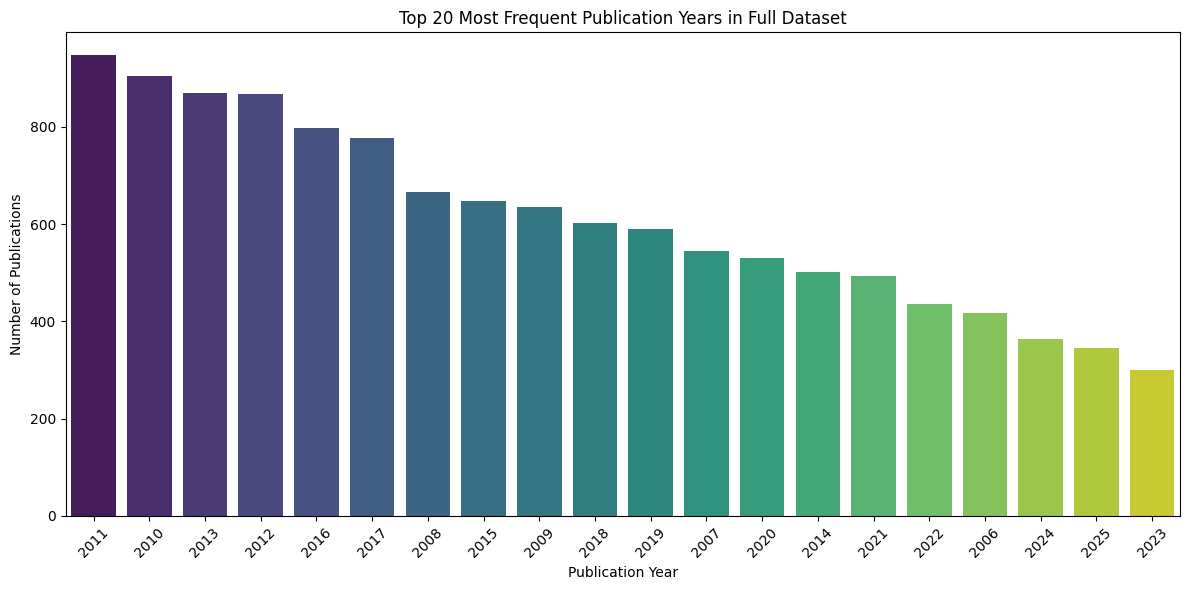

In [ ]:
# Analyze the distribution of publication years for the full dataset
year_counts_full = df_full['year'].value_counts().sort_index()

# Filter out non-numeric years if any, or years that are unlikely (e.g., single digits)
# This pattern matches exactly four digits, ensuring only valid years are considered
year_counts_full = year_counts_full[year_counts_full.index.astype(str).str.match(r'^\d{4}$', na=False)]

# Convert index to integer for proper sorting and comparison
year_counts_full.index = year_counts_full.index.astype(int)
year_counts_full = year_counts_full[year_counts_full.index > 1900] # Assuming publications are after 1900

# Get the top N years for better visualization, adjust N as needed
top_n_years = year_counts_full.nlargest(20)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_n_years.index.astype(str), y=top_n_years.values, hue=top_n_years.index.astype(str), palette='viridis', legend=False)
plt.title('Top 20 Most Frequent Publication Years in Full Dataset')
plt.xlabel('Publication Year')
plt.ylabel('Number of Publications')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Visualize Distribution of Subjects (Full Dataset)

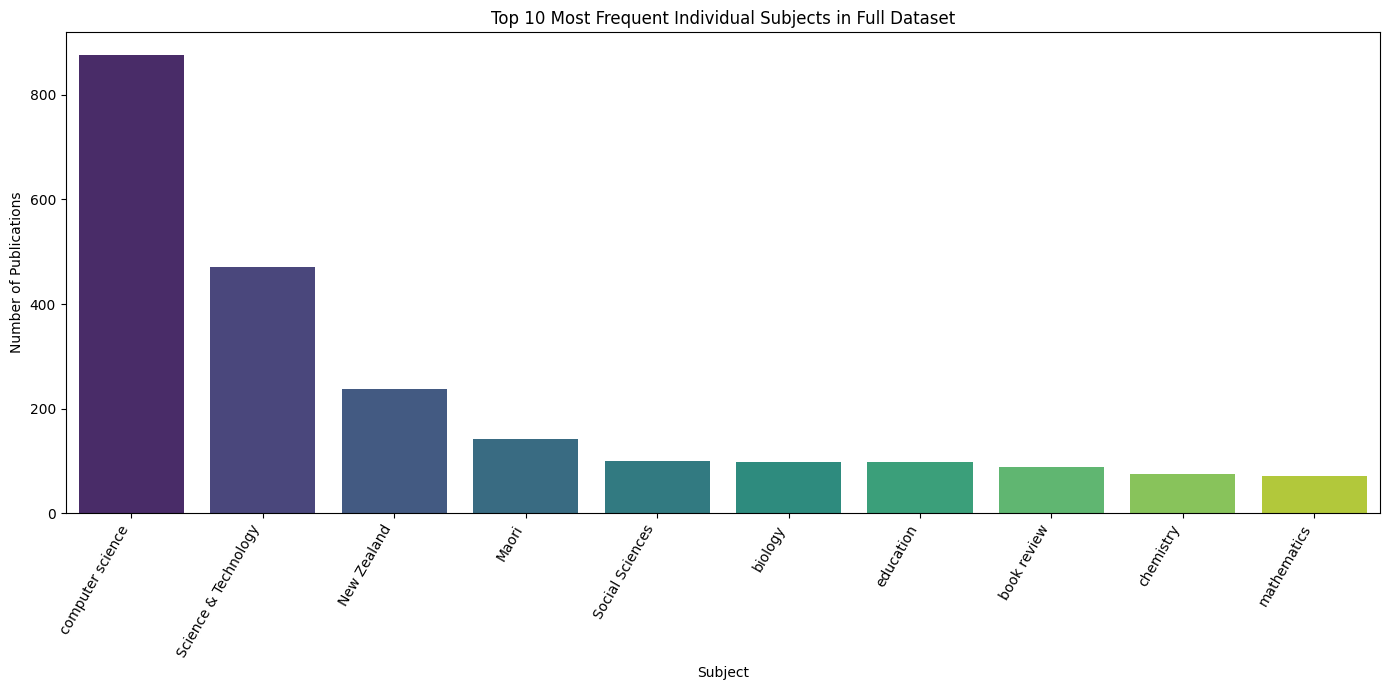

In [ ]:
# Analyze the distribution of subjects for the full dataset
# Using the cleaned and exploded subjects for a more accurate count of individual subjects
subject_counts_full_exploded = df_exploded_subjects['subjects_list'].value_counts()

# Get the top 10 most frequent individual subjects
top_10_subjects_exploded = subject_counts_full_exploded.nlargest(10)

plt.figure(figsize=(14, 7))
sns.barplot(x=top_10_subjects_exploded.index, y=top_10_subjects_exploded.values, hue=top_10_subjects_exploded.index, palette='viridis', legend=False)
plt.title('Top 10 Most Frequent Individual Subjects in Full Dataset')
plt.xlabel('Subject')
plt.ylabel('Number of Publications')
plt.xticks(rotation=60, ha='right') # Rotate labels for better readability
plt.tight_layout()
plt.show()

### Clean and Explode Subjects for Detailed Analysis

In [ ]:
# Ensure 'subjects' is a string before splitting to avoid errors
df_full['subjects'] = df_full['subjects'].fillna('').astype(str)

# Split and explode subjects
df_full['subjects_list'] = df_full['subjects'].apply(lambda x: [s.strip() for s in x.replace(',', ';').split(';') if s.strip()])
df_exploded_subjects = df_full.explode('subjects_list')

# Get the counts
individual_subject_counts = df_exploded_subjects['subjects_list'].value_counts()

print("Top 10 Most Frequent Individual Subjects (Full Dataset):")
display(individual_subject_counts.head(10))

Top 10 Most Frequent Individual Subjects (Full Dataset):


,count
subjects_list,
computer science,876
Science & Technology,470
New Zealand,237
Maori,141
Social Sciences,100
biology,98
education,97
book review,89
chemistry,75


### Top Authors Analysis

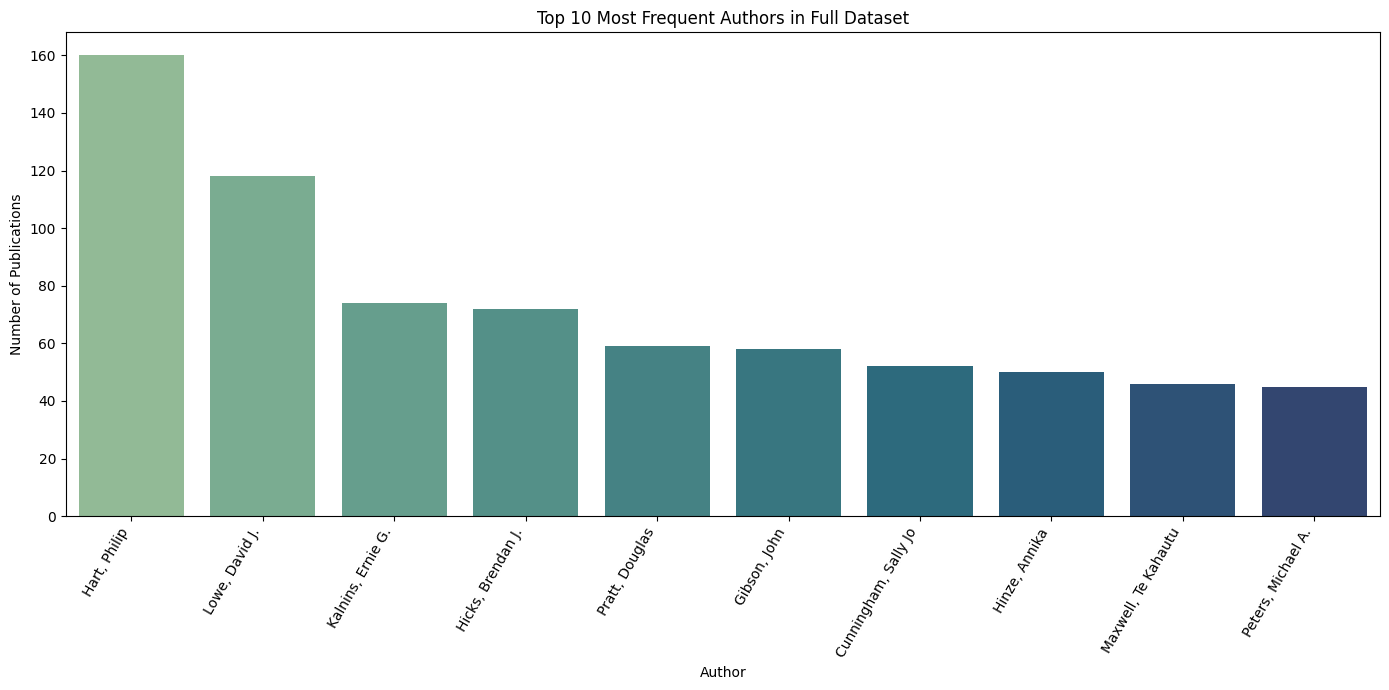

In [ ]:
# Analyze the distribution of authors for the full dataset
# Split authors if multiple are listed (assuming ';' as delimiter)
authors_list = df_full['authors'].apply(lambda x: [a.strip() for a in str(x).split(';') if a.strip()])

# Create a list of all individual authors
all_authors = [author for sublist in authors_list for author in sublist]

# Count the occurrences of each author
author_counts = pd.Series(all_authors).value_counts()

# Get the top 10 most frequent authors
top_10_authors = author_counts.nlargest(10)

plt.figure(figsize=(14, 7))
sns.barplot(x=top_10_authors.index, y=top_10_authors.values, hue=top_10_authors.index, palette='crest', legend=False)
plt.title('Top 10 Most Frequent Authors in Full Dataset')
plt.xlabel('Author')
plt.ylabel('Number of Publications')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

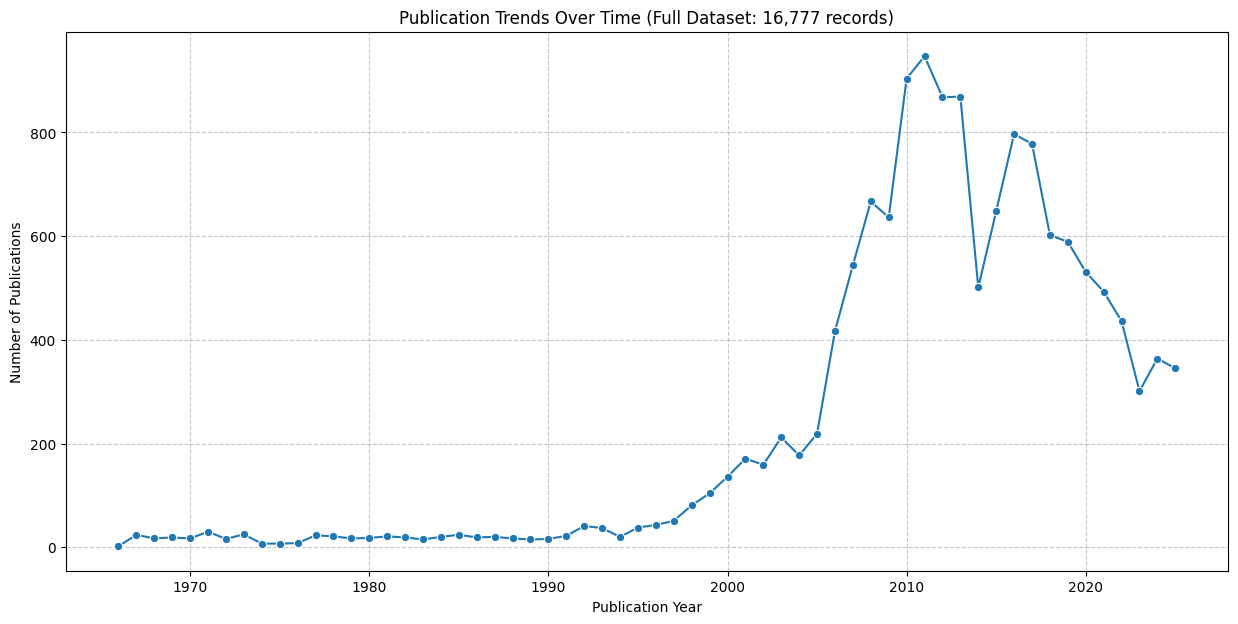

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Clean years for the full dataset
df_full['year_clean'] = pd.to_numeric(df_full['year'], errors='coerce')
year_trends = df_full[df_full['year_clean'].between(1900, 2025)]['year_clean'].value_counts().sort_index()

# Create the line plot
plt.figure(figsize=(15, 7))
sns.lineplot(x=year_trends.index, y=year_trends.values, marker='o')
plt.title('Publication Trends Over Time (Full Dataset: 16,777 records)')
plt.xlabel('Publication Year')
plt.ylabel('Number of Publications')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
df_full.loc[:, 'year'] = pd.to_numeric(df_full['year'], errors='coerce')
df_full = df_full[df_full['year'].between(1900, 2100)] # Filter for reasonable year range
df_full.loc[:, 'year'] = df_full['year'].astype(int)

In [ ]:
# Calculate publications per decade for the full dataset
df_full['year_int'] = pd.to_numeric(df_full['year'], errors='coerce')
df_full_valid = df_full[df_full['year_int'].between(1900, 2025)].copy()
df_full_valid['decade'] = (df_full_valid['year_int'] // 10) * 10

publications_per_decade = df_full_valid['decade'].value_counts().sort_index()

print("Publications per Decade (Full Dataset):")
display(publications_per_decade)

average_publications_per_decade = publications_per_decade.mean()
print(f"\nAverage number of publications per decade: {average_publications_per_decade:.2f}")

Publications per Decade (Full Dataset):


/tmp/ipykernel_14876/4033047587.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_full['year_int'] = pd.to_numeric(df_full['year'], errors='coerce')


,count
decade,
1960,62
1970,171
1980,188
1990,453
2000,3338
2010,7503
2020,2470



Average number of publications per decade: 2026.43


In [ ]:
# Detailed breakdown for the current decade (2020s)
publications_2020s = df_full_valid[df_full_valid['decade'] == 2020]
publications_per_year_2020s = publications_2020s['year_int'].value_counts().sort_index()

print("Publication count for each year in the 2020s (Full Dataset):")
display(publications_per_year_2020s)

Publication count for each year in the 2020s (Full Dataset):


,count
year_int,
2020,531
2021,493
2022,436
2023,301
2024,364
2025,345


In [ ]:
print(f"Total number of publications across all years: {len(df_full)}")

Total number of publications across all years: 14218


### Investigating Potential Duplicates with Different Years
We will group by title and look for records that have different years to see if they are truly distinct (e.g., serial publications).

In [ ]:
# Find titles that appear in multiple years
title_year_check = df_full.groupby('title')['year'].nunique()
titles_with_multiple_years = title_year_check[title_year_check > 1].index

# Display examples of these titles to see if they are distinct entities
print(f"Found {len(titles_with_multiple_years)} titles spanning multiple years.")
display(df_full[df_full['title'].isin(titles_with_multiple_years)].sort_values(['title', 'year'])[['title', 'year', 'authors', 'record_id_hash']].head(20))

Found 29 titles spanning multiple years.


,title,year,authors,record_id_hash
11556,Additive manufacturing of hygromorphic structu...,2022,"Gauss, Christian",31c1ed876371a0ea140135a4bb5f8589627482a7b62062...
6497,Additive manufacturing of hygromorphic structu...,2023,"Gauss, Christian",c3fb7835e4dd53614bf4ef7503785b2ae6ff8fb87f90be...
12585,Are zooplankton invasions in constructed water...,2010,"Parkes, Samantha Maree",fbd6c3c32865e1c6af9b28108abe95f0e36609c821be20...
11658,Are zooplankton invasions in constructed water...,2012,"Parkes, Samantha Maree",b1bb1542f6182a13d1245462970417f9ae50af52f62542...
9500,Book reviews and Book notices,1967,Waikato Geological Society,76c0eb2d270ba6449e2e456ae3d740c757f55309480670...
6781,Book reviews and Book notices,1968,Waikato Geological Society,eec15b76e99191250472a26db8502a385599b80006539b...
10758,Book reviews and Book notices,1969,Waikato Geological Society,853485bf4c20f388115938c60f29a7aec959730adef088...
12707,Book reviews and Book notices,1969,Waikato Geological Society,0c9be8f42cfb3989cf92975bf4f1e411438674b10a4b2e...
298,Book reviews and Book notices,1970,Waikato Geological Society,2b4d44b541a9a8c8854c555e8bda4ca9ad9e3cdded7fa4...
8204,Book reviews and Book notices,1971,Waikato Geological Society,babbb410c3254520f6e97648face0ad95e3799734961ee...


In [ ]:
title_counts = df_full['title'].value_counts()
duplicate_titles = title_counts[title_counts > 1]

print(f"Total unique titles: {df_full['title'].nunique()}")
print(f"Number of titles with duplicates: {len(duplicate_titles)}")

if len(duplicate_titles) > 0:
    print("\nTop 10 most frequent titles:")
    display(duplicate_titles.head(10))
else:
    print("No duplicate titles found.")

Total unique titles: 14121
Number of titles with duplicates: 49

Top 10 most frequent titles:


,count
title,
Editorial,14
Introduction,11
Coverpage and Contents,10
Review: Marine natural products,7
Book reviews and Book notices,6
New Zealand,5
Composition Portfolio,5
He Puna Kōrero Journal of Maori and Pacific Development,3
Comment,3


In [ ]:
# Let's inspect the records that share the title 'Editorial'
duplicate_title_example = 'Editorial'
inspection_df = df_full[df_full['title'] == duplicate_title_example]

print(f"Displaying records with the title: '{duplicate_title_example}'")
display(inspection_df[['record_id_hash', 'title', 'authors', 'year', 'subjects']])

Displaying records with the title: 'Editorial'


,record_id_hash,title,authors,year,subjects
340,a01edf2ab60512b642a1db8f943daea7d1ff0f1f359ae7...,Editorial,"Bray, Peter",2023,
1189,4cd775398559253f578452a0cbec535e4df5d82f8bdedd...,Editorial,"Findsen, Brian",2017,
2881,5dfb22a80818b934b77a9bd007f1cff6bcbf683899a386...,Editorial,"Clarkin-Phillips, Jeanette",2019,
6244,955c993c6948df1a3f98aa822ac23729371c245b074457...,Editorial,"Coleman, Claire",2022,
7020,57b9e58c6f2d3d2b7d45ac416d81672ab62e10eb886a78...,Editorial,"Strachan, Jane",2011,education
7855,94d0a146a5ab2dacc7df63e410efb8a1c444e09c8d5869...,Editorial,"Longley, Alys",2017,
7926,e27919d6c401cd6d93af6ac8cbe4ae4fcd57b86d36625b...,Editorial,"Locke, Terry",2002,curriculum
10071,405f708ab63242d88a79696093fc8dfe69359eaf68ad94...,Editorial,"Shieff, Sarah",2011,
10643,c707121ba68aa7c63ee489607148c93a162c26cd9b39f7...,Editorial,"Wright, Noeline",2011,primary schools
11135,74202b82c3a3b795c853450a2dab672df88647ee3c89a8...,Editorial,Waikato Geological Society,1967,


In [ ]:
# Get all rows where the title is duplicated
duplicate_titles_df = df_full[df_full.duplicated(subset=['title'], keep=False)]

# Sort by title to see them together
print(f"Found {len(duplicate_titles_df)} rows that share a title with at least one other record.")
display(duplicate_titles_df.sort_values(by='title')[['title', 'authors', 'year', 'abstract']].head(20))

Found 146 rows that share a title with at least one other record.


,title,authors,year,abstract
11556,Additive manufacturing of hygromorphic structu...,"Gauss, Christian",2022,Three-dimensional printing technologies are at...
6497,Additive manufacturing of hygromorphic structu...,"Gauss, Christian",2023,Three-dimensional printing technologies are at...
11658,Are zooplankton invasions in constructed water...,"Parkes, Samantha Maree",2012,Aim Constructed water bodies (e.g. water suppl...
12585,Are zooplankton invasions in constructed water...,"Parkes, Samantha Maree",2010,The invasion of non-indigenous species is cons...
6781,Book reviews and Book notices,Waikato Geological Society,1968,"Book reviews and Book notices from Volume 2, N..."
8204,Book reviews and Book notices,Waikato Geological Society,1971,"Book reviews and Book notice from Volume 5, Nu..."
10758,Book reviews and Book notices,Waikato Geological Society,1969,"Book reviews and Book notices from Volume 3, N..."
12707,Book reviews and Book notices,Waikato Geological Society,1969,"Book reviews and Book notice from Volume 3, Nu..."
9500,Book reviews and Book notices,Waikato Geological Society,1967,"Book reviews and Book notice from Volume 1, Nu..."
298,Book reviews and Book notices,Waikato Geological Society,1970,"Book reviews and Book notices from Volume 4, N..."


### Separating Unique Data and Duplicate Groups
We will create one dataset containing only the unique records and another containing all instances of duplicates for further analysis.

In [ ]:
# 1. Dataset with unique records only (deduplicated)
df_full_unique = df_full_raw.drop_duplicates(subset=['title', 'abstract'], keep='first').copy()

# 2. Dataset containing ALL records that have at least one duplicate
# (including both the original and the copies)
df_duplicates_all = df_full_raw[df_full_raw.duplicated(subset=['title', 'abstract'], keep=False)].copy()

print(f"Unique records dataset size: {len(df_full_unique)}")
print(f"Dataset containing all duplicate instances size: {len(df_duplicates_all)}")

# Displaying the first few rows of the duplicates dataset to verify
display(df_duplicates_all.sort_values(by=['title']).head(10))

Unique records dataset size: 16777
Dataset containing all duplicate instances size: 34


,record_id,title,authors,year,subjects,abstract,url
8382,,A robust semantics hides fewer errors,"Reeves, Steve",2009,computer science,In this paper we explore how formal models are...,
15908,,A robust semantics hides fewer errors,"Reeves, Steve",2009-06-10,computer science,In this paper we explore how formal models are...,
13157,,Best intentions: Using convergent practices di...,"Whyte, Barbara",2017,Summative assessment,Summative assessment and explicit teaching are...,
2439,,Best intentions: Using convergent practices di...,"Whyte, Barbara",2017,Summative assessment,Summative assessment and explicit teaching are...,
3876,,Constructing programs or processes,"Reeves, Steve",2005-12-28,cause,"We define interacting sequential programs, mot...",
16018,,Constructing programs or processes,"Reeves, Steve",2005-12,,"We define interacting sequential programs, mot...",
16446,,Creating a curriculum for indigenous and commu...,"Bruce, Ian",2002-02,Te reo Māori,Part 1 of this paper introduces the draft Comm...,
470,,Creating a curriculum for indigenous and commu...,"Bruce, Ian",2002,linguistics,Part 1 of this paper introduces the draft Comm...,
7385,,Current singularities at finitely compressible...,"Dmitruk, Pablo",2005-07-15,mathematics,The formation of current singularities at line...,
9793,,Current singularities at finitely compressible...,"Pontin, D.I.",2005,,The formation of current singularities at line...,


### Exporting and Downloading Data
We will save both the unique dataset and the duplicate instances to CSV files and initiate the download.

In [ ]:
from google.colab import files

# Save files locally in the Colab environment
unique_filename = 'waikato_full_unique_16777.csv'
duplicates_filename = 'waikato_duplicates_all.csv'

df_full_unique.to_csv(unique_filename, index=False)
df_duplicates_all.to_csv(duplicates_filename, index=False)

print(f"Saved {unique_filename} and {duplicates_filename}.")

# Trigger browser downloads
files.download(unique_filename)
files.download(duplicates_filename)

Saved waikato_full_unique_16777.csv and waikato_duplicates_all.csv.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(f'Count of unique records: {len(df_full_unique)}')
print(f'Count of all duplicate records: {len(df_duplicates_all)}')

Count of unique records: 16777
Count of all duplicate records: 34


## Independent Analysis: Unique Dataset
This section focuses exclusively on the properties of the 16,777 unique records.

Summary for Unique Dataset (16777 rows):


,record_id,title,authors,year,subjects,abstract,url,status
count,16777,16777,16777,16777,16777,16777,16777,16777
unique,1,16636,8034,1325,7121,16637,1,1
top,,Editorial,"Hart, Philip",2011,,,,Unique
freq,16777,14,160,947,4827,99,16777,16777


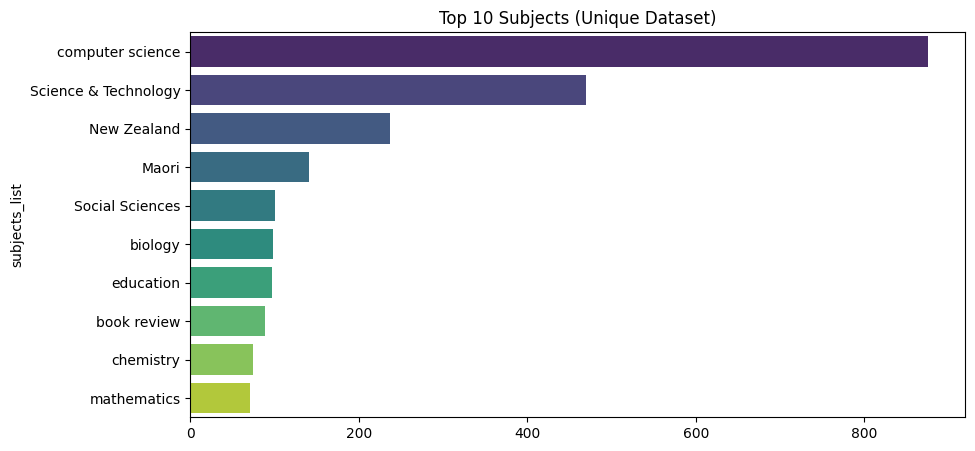

In [ ]:
# Analysis of Unique Dataset
print(f"Summary for Unique Dataset ({len(df_full_unique)} rows):")
display(df_full_unique.describe(include='all'))

# Unique Subject Distribution
df_unique_subjects = df_full_unique.copy()
df_unique_subjects['subjects_list'] = df_unique_subjects['subjects'].fillna('').astype(str).apply(lambda x: [s.strip() for s in x.replace(',', ';').split(';') if s.strip()])
unique_subj_counts = df_unique_subjects.explode('subjects_list')['subjects_list'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=unique_subj_counts.values, y=unique_subj_counts.index, palette='viridis', hue=unique_subj_counts.index, legend=False)
plt.title('Top 10 Subjects (Unique Dataset)')
plt.show()

## Independent Analysis: Duplicate Dataset
This section analyzes the 34 records that were identified as duplicates during the scraping process.

Summary for Duplicate Dataset (34 rows):


,record_id,title,authors,year,subjects,abstract,url,status,subjects_list
count,34,34,34,34,34,34,34,34,34
unique,1,17,20,19,17,17,1,1,17
top,,Ensembles of nested dichotomies for multi-clas...,"Reeves, Steve",2017,,Nested dichotomies are a standard statistical ...,,Duplicate,[]
freq,34,2,4,8,14,2,34,34,14


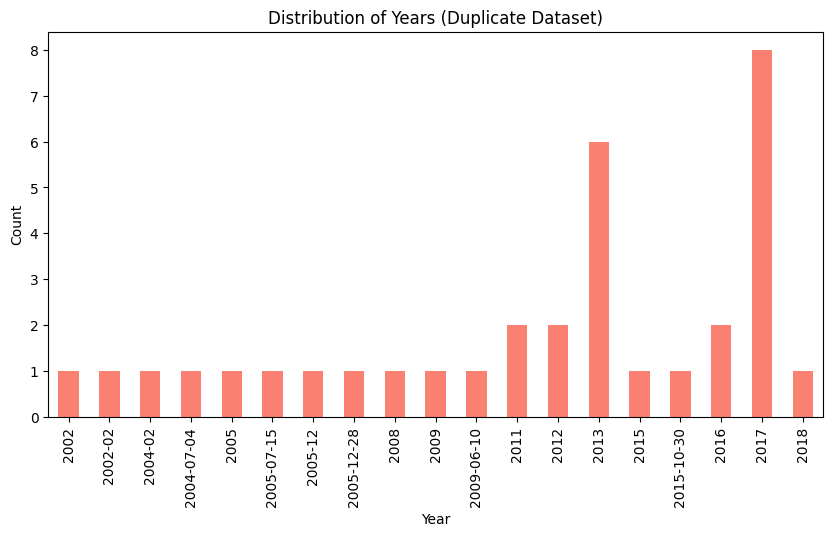

In [ ]:
# Analysis of Duplicate Dataset
print(f"Summary for Duplicate Dataset ({len(df_duplicates_all)} rows):")
display(df_duplicates_all.describe(include='all'))

# Duplicate Year Distribution
dup_year_counts = df_duplicates_all['year'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
dup_year_counts.plot(kind='bar', color='salmon')
plt.title('Distribution of Years (Duplicate Dataset)')
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()

In [ ]:
# Display all rows in the duplicate dataset, sorted by year and title
pd.set_option('display.max_rows', None)
display(df_duplicates_all.sort_values(by=['year', 'title']))
# Reset option to default
pd.reset_option('display.max_rows')

,record_id,title,authors,year,subjects,abstract,url,status,subjects_list
470,,Creating a curriculum for indigenous and commu...,"Bruce, Ian",2002,linguistics,Part 1 of this paper introduces the draft Comm...,,Duplicate,[linguistics]
16446,,Creating a curriculum for indigenous and commu...,"Bruce, Ian",2002-02,Te reo Māori,Part 1 of this paper introduces the draft Comm...,,Duplicate,[Te reo Māori]
15954,,Ensembles of nested dichotomies for multi-clas...,"Frank, Eibe",2004-02,computer science,Nested dichotomies are a standard statistical ...,,Duplicate,[computer science]
25,,Ensembles of nested dichotomies for multi-clas...,"Frank, Eibe\n",2004-07-04,,Nested dichotomies are a standard statistical ...,,Duplicate,[]
9793,,Current singularities at finitely compressible...,"Pontin, D.I.",2005,,The formation of current singularities at line...,,Duplicate,[]
7385,,Current singularities at finitely compressible...,"Dmitruk, Pablo",2005-07-15,mathematics,The formation of current singularities at line...,,Duplicate,[mathematics]
16018,,Constructing programs or processes,"Reeves, Steve",2005-12,,"We define interacting sequential programs, mot...",,Duplicate,[]
3876,,Constructing programs or processes,"Reeves, Steve",2005-12-28,cause,"We define interacting sequential programs, mot...",,Duplicate,[cause]
15582,,Dusty horizons,"Lowe, David J.",2008,,Dust whipped up and deposited by wind forms sh...,,Duplicate,[]
8382,,A robust semantics hides fewer errors,"Reeves, Steve",2009,computer science,In this paper we explore how formal models are...,,Duplicate,[computer science]


In [ ]:
# Find and display all records that share the same title in the final cleaned dataset
# Using df_full which contains the unique records and the record_id_hash column
title_duplicates = df_full[df_full.duplicated(subset=['title'], keep=False)]
print(f"Found {len(title_duplicates)} records that share titles with others.")

# Set display options to show all rows for this specific investigation
pd.set_option('display.max_rows', None)
display(title_duplicates.sort_values('title')[['title', 'authors', 'year', 'record_id_hash']])
pd.reset_option('display.max_rows')

Found 146 records that share titles with others.


,title,authors,year,record_id_hash
11556,Additive manufacturing of hygromorphic structu...,"Gauss, Christian",2022,31c1ed876371a0ea140135a4bb5f8589627482a7b62062...
6497,Additive manufacturing of hygromorphic structu...,"Gauss, Christian",2023,c3fb7835e4dd53614bf4ef7503785b2ae6ff8fb87f90be...
11658,Are zooplankton invasions in constructed water...,"Parkes, Samantha Maree",2012,b1bb1542f6182a13d1245462970417f9ae50af52f62542...
12585,Are zooplankton invasions in constructed water...,"Parkes, Samantha Maree",2010,fbd6c3c32865e1c6af9b28108abe95f0e36609c821be20...
6781,Book reviews and Book notices,Waikato Geological Society,1968,eec15b76e99191250472a26db8502a385599b80006539b...
8204,Book reviews and Book notices,Waikato Geological Society,1971,babbb410c3254520f6e97648face0ad95e3799734961ee...
10758,Book reviews and Book notices,Waikato Geological Society,1969,853485bf4c20f388115938c60f29a7aec959730adef088...
12707,Book reviews and Book notices,Waikato Geological Society,1969,0c9be8f42cfb3989cf92975bf4f1e411438674b10a4b2e...
9500,Book reviews and Book notices,Waikato Geological Society,1967,76c0eb2d270ba6449e2e456ae3d740c757f55309480670...
298,Book reviews and Book notices,Waikato Geological Society,1970,2b4d44b541a9a8c8854c555e8bda4ca9ad9e3cdded7fa4...


In [ ]:
# Check for duplicates using Abstract and Authors
abstract_author_duplicates = df_full[df_full.duplicated(subset=['abstract', 'authors'], keep=False)]

# Filter out cases where both abstract and authors might be empty to avoid false positives
abstract_author_duplicates = abstract_author_duplicates[abstract_author_duplicates['abstract'].fillna('').str.len() > 0]

print(f"Number of records sharing the same Abstract and Author: {len(abstract_author_duplicates)}")

if len(abstract_author_duplicates) > 0:
    print("\nDisplaying records with identical Abstract and Author:")
    display(abstract_author_duplicates.sort_values(by=['authors', 'abstract'])[['title', 'authors', 'year', 'record_id_hash']].head(20))
else:
    print("No records found with identical Abstract and Author.")

Number of records sharing the same Abstract and Author: 22

Displaying records with identical Abstract and Author:


,title,authors,year,record_id_hash
1318,Using scratch to facilitate mathematical thinking,"Calder, Nigel Stuart",2018,435119b8042e5a1e922aa24f01d769c4aac3e1686904fd...
4650,Using Scratch to facilitate mathematical thinking,"Calder, Nigel Stuart",2018,924999ba49e82ab030e8bdeb0745b703f305bfa6fecbbe...
4431,The nutritional content of supermarket beverag...,"Chepulis, Lynne Merran",2018,94a5cdfb02fcdf32d977c81447e2b8289eaeb717030ff4...
9422,The nutritional content of supermarket beverag...,"Chepulis, Lynne Merran",2018,a2c6f537a4396b25dc8354942f1d0806c8fa5866d13434...
11386,An Empirical Comparison of Exact Nearest Neigh...,"Frank, Eibe",2007,fd42d27645ab3be23c072a5e182e6abb388d1bd69cd9da...
11628,Improving on bagging with input smearing,"Frank, Eibe",2006,bcad3933ee79142f85313913024080676d7fdaf0db73a0...
3223,Design and the fourth industrial revolution. D...,"García Ferrari, Tomás",2017,927aeef02094ad15351afd5a26280f669042c2e5099dd1...
11170,Design and the fourth industrial revolution,"García Ferrari, Tomás",2017,1d63963822aa208ac0e71902f7935b9c94c26a9fd3cff1...
4481,Evaluating an online learning community: Intel...,"Khoo, Elaine G.L.",2011,2a9c3597cfbe758e59eba2348da7445f6288791bfed4f1...
6413,Evaluating an online learning community: Intel...,"Khoo, Elaine G.L.",2015,7f2be37944dfe5ed0dfaee5573ef35d13813d9ae94433c...


In [ ]:
# Inspect the full metadata for a specific title to see the context of 'duplicates'
target_title = 'Editorial'  # Change this to any title from the list above

inspection_results = df_full[df_full['title'] == target_title]

print(f"Found {len(inspection_results)} entries for title: '{target_title}'")
display(inspection_results[['year', 'authors', 'abstract', 'url', 'record_id_hash']])

Found 14 entries for title: 'Editorial'


,year,authors,abstract,url,record_id_hash
340,2023,"Bray, Peter","The Volume 43(1) editorial of the ""New Zealand...",,a01edf2ab60512b642a1db8f943daea7d1ff0f1f359ae7...
1189,2017,"Findsen, Brian",This special issue of the International Journa...,,4cd775398559253f578452a0cbec535e4df5d82f8bdedd...
2881,2019,"Clarkin-Phillips, Jeanette",As New Zealand contemplates wholesale review o...,,5dfb22a80818b934b77a9bd007f1cff6bcbf683899a386...
6244,2022,"Coleman, Claire","Frequently marginalised and maligned, the arts...",,955c993c6948df1a3f98aa822ac23729371c245b074457...
7020,2011,"Strachan, Jane",An introduction is presented in which the edit...,,57b9e58c6f2d3d2b7d45ac416d81672ab62e10eb886a78...
7855,2017,"Longley, Alys",Welcome to Volume 5 of Dance Research Aotearoa...,,94d0a146a5ab2dacc7df63e410efb8a1c444e09c8d5869...
7926,2002,"Locke, Terry",The scrutiny of any educational system inevita...,,e27919d6c401cd6d93af6ac8cbe4ae4fcd57b86d36625b...
10071,2011,"Shieff, Sarah",This issue also presents new work from an unus...,,405f708ab63242d88a79696093fc8dfe69359eaf68ad94...
10643,2011,"Wright, Noeline",An introduction is presented in which the edit...,,c707121ba68aa7c63ee489607148c93a162c26cd9b39f7...
11135,1967,Waikato Geological Society,The production of yet another new journal requ...,,74202b82c3a3b795c853450a2dab672df88647ee3c89a8...


In [ ]:
# Check for duplicates using Title and Authors
title_author_duplicates = df_full[df_full.duplicated(subset=['title', 'authors'], keep=False)]

print(f"Number of records sharing the same Title and Author: {len(title_author_duplicates)}")

if len(title_author_duplicates) > 0:
    print("\nDisplaying records with identical Title and Author (sorted to see pairs):")
    display(title_author_duplicates.sort_values(by=['title', 'authors'])[['title', 'authors', 'year', 'record_id_hash']].head(20))
else:
    print("No records found with identical Title and Author.")

Number of records sharing the same Title and Author: 96

Displaying records with identical Title and Author (sorted to see pairs):


,title,authors,year,record_id_hash
6497,Additive manufacturing of hygromorphic structu...,"Gauss, Christian",2023,c3fb7835e4dd53614bf4ef7503785b2ae6ff8fb87f90be...
11556,Additive manufacturing of hygromorphic structu...,"Gauss, Christian",2022,31c1ed876371a0ea140135a4bb5f8589627482a7b62062...
11658,Are zooplankton invasions in constructed water...,"Parkes, Samantha Maree",2012,b1bb1542f6182a13d1245462970417f9ae50af52f62542...
12585,Are zooplankton invasions in constructed water...,"Parkes, Samantha Maree",2010,fbd6c3c32865e1c6af9b28108abe95f0e36609c821be20...
298,Book reviews and Book notices,Waikato Geological Society,1970,2b4d44b541a9a8c8854c555e8bda4ca9ad9e3cdded7fa4...
6781,Book reviews and Book notices,Waikato Geological Society,1968,eec15b76e99191250472a26db8502a385599b80006539b...
8204,Book reviews and Book notices,Waikato Geological Society,1971,babbb410c3254520f6e97648face0ad95e3799734961ee...
9500,Book reviews and Book notices,Waikato Geological Society,1967,76c0eb2d270ba6449e2e456ae3d740c757f55309480670...
10758,Book reviews and Book notices,Waikato Geological Society,1969,853485bf4c20f388115938c60f29a7aec959730adef088...
12707,Book reviews and Book notices,Waikato Geological Society,1969,0c9be8f42cfb3989cf92975bf4f1e411438674b10a4b2e...


### Clarifying Title 'Duplicates' vs. Content Duplicates
This check shows that while 146 records share titles, they are distinct entries (like different editions or different authors using the same generic title).

In [ ]:
# Show the breakdown of the most common shared titles in the 'unique' dataset
shared_titles = df_full[df_full.duplicated(subset=['title'], keep=False)]
title_breakdown = shared_titles.groupby('title').size().sort_values(ascending=False)

print(f"Total unique titles that appear more than once: {len(title_breakdown)}")
print("Top shared titles (distinct records with identical names):")
display(title_breakdown.head(10))

Total unique titles that appear more than once: 49
Top shared titles (distinct records with identical names):


,0
title,
Editorial,14
Introduction,11
Coverpage and Contents,10
Review: Marine natural products,7
Book reviews and Book notices,6
Composition Portfolio,5
New Zealand,5
He Puna Kōrero Journal of Maori and Pacific Development,3
Comment,3
